##  LSTM Autoencoder for UAV anomaly score generation


Pipeline:
  Train LSTM Autoencoder on normal flights only
  → Calculate reconstruction error
  → Use reconstruction error as anomaly_score
  → Save train/val/test datasets with anomaly_score

THESIS JUSTIFICATION NOTES (answers supervisor questions):

What is a "normal" flight?
  Flights are labelled normal/abnormal based on dataset_label,
  which was assigned during data preprocessing (notebook 01-03)
  using flight-level criteria such as absence of extreme power
  draws, no sensor dropout, and no log anomalies flagged by
  PX4. The label is NOT derived from battery data used here,
  so there is no circular validation.

Why train only on normal flights?
  The LSTM Autoencoder learns the reconstruction of normal UAV
  temporal battery behaviour. Flights that deviate from normal
  patterns produce higher reconstruction error (anomaly_score).
  This is the standard one-class anomaly detection approach
  (Malhotra et al., 2016).

Why SEQ_LEN=100 (10 seconds)?
  At 10 Hz, 100 rows = 10 seconds. This window captures a
  full hover-to-manoeuvre-to-hover cycle typical in quadrotor
  flights. Windows shorter than 5 s miss the full dynamic;
  windows longer than 30 s risk blending distinct flight phases.
  10 s is used as the primary setting; sensitivity to this
  choice is acknowledged in the thesis.

Why MSE as reconstruction loss?
  MSE penalises large deviations more than small ones, making
  it sensitive to unusual spikes in battery voltage, current,
  or power — the signals most relevant to anomaly detection
  in UAV energy behaviour.

 Why repeat the latent vector as decoder input?
  The encoder compresses the full 10-second sequence into a
  single latent vector via the final LSTM hidden state. The
  decoder then reconstructs the sequence from this vector by
  repeating it across time steps. This forces the latent space
  to capture the most salient temporal structure. The decoder
  LSTM still learns timestep-level reconstruction patterns.
  This is consistent with the architecture in Malhotra et al.
  (2016) and Srivastava et al. (2015).

In [33]:
%pip install torch torchvision torchaudio scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 1. Imports

In [34]:
import os
import random
from pathlib import Path
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
 
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
 
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
)
 
print("PyTorch version:", torch.__version__)

PyTorch version: 2.12.1


## 2. delete output files

In [35]:
# ============================================================
# DELETE OLD OUTPUT FILES BEFORE RE-RUNNING
# Run this cell once, then comment it out
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_anomaly_score")

files_to_delete = [
    OUTPUT_DIR / "train_no_dr_with_anomaly_score.csv",
    OUTPUT_DIR / "val_no_dr_with_anomaly_score.csv",
    OUTPUT_DIR / "test_no_dr_with_anomaly_score.csv",
    OUTPUT_DIR / "best_lstm_autoencoder.pt",
]

for f in files_to_delete:
    if f.exists():
        f.unlink()
        print(f"Deleted: {f.name}")
    else:
        print(f"Not found (already clean): {f.name}")

print("\nCleanup done. Safe to re-run the notebook.")

Deleted: train_no_dr_with_anomaly_score.csv
Deleted: val_no_dr_with_anomaly_score.csv
Deleted: test_no_dr_with_anomaly_score.csv
Deleted: best_lstm_autoencoder.pt

Cleanup done. Safe to re-run the notebook.


In [36]:
# setting seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [37]:

# GPU: Device setup
if torch.backends.mps.is_available():
    device = torch.device("mps")
    torch.mps.manual_seed(SEED)   # MPS seed for Apple Silicon
    print("Using Apple Silicon GPU: MPS")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    print("Using CUDA GPU")
else:
    device = torch.device("cpu")
    print("Using CPU")
 
print("Device:", device)

Using Apple Silicon GPU: MPS
Device: mps


In [38]:
# Project paths
BASE_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
 
OUTPUT_DIR = BASE_DIR / "model_outputs" / "lstm_autoencoder_anomaly_score"
PLOT_DIR = OUTPUT_DIR / "plots"
 
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
 
print("Base directory:", BASE_DIR)
print("Output directory:", OUTPUT_DIR)

Base directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project
Output directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_anomaly_score


In [39]:
# CELL 6: Deleting old outputs
files_to_delete = [
    OUTPUT_DIR / "train_no_dr_with_anomaly_score.csv",
    OUTPUT_DIR / "val_no_dr_with_anomaly_score.csv",
    OUTPUT_DIR / "test_no_dr_with_anomaly_score.csv",
    OUTPUT_DIR / "best_lstm_autoencoder.pt",
]
 
for f in files_to_delete:
    if f.exists():
        f.unlink()
        print(f"Deleted: {f.name}")
    else:
        print(f"Already clean: {f.name}")
 
print("Cleanup done.")

Already clean: train_no_dr_with_anomaly_score.csv
Already clean: val_no_dr_with_anomaly_score.csv
Already clean: test_no_dr_with_anomaly_score.csv
Already clean: best_lstm_autoencoder.pt
Cleanup done.


In [40]:
# dataset loading
def find_file(root_dir, possible_names):
    for name in possible_names:
        matches = list(root_dir.rglob(name))
        if matches:
            print(f"Found: {matches[0]}")
            return matches[0]
    raise FileNotFoundError(f"Could not find any of: {possible_names}")
 
 
train_path = find_file(BASE_DIR, ["train_no_dr_scaled.csv", "train_no_dr_imputed_scaled.csv"])
val_path   = find_file(BASE_DIR, ["val_no_dr_scaled.csv",   "val_no_dr_imputed_scaled.csv"])
test_path  = find_file(BASE_DIR, ["test_no_dr_scaled.csv",  "test_no_dr_imputed_scaled.csv"])

Found: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/train_no_dr_scaled.csv
Found: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/val_no_dr_scaled.csv
Found: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/test_no_dr_scaled.csv


In [41]:
train_df = pd.read_csv(train_path)
val_df   = pd.read_csv(val_path)
test_df  = pd.read_csv(test_path)
 
print("Train shape:", train_df.shape)
print("Val shape:  ", val_df.shape)
print("Test shape: ", test_df.shape)

Train shape: (694549, 14)
Val shape:   (138749, 14)
Test shape:  (138524, 14)


In [42]:
# Split composition audit 
# Show exactly how many normal/abnormal flights are in each split.
print("\n" + "="*60)
print("SPLIT COMPOSITION AUDIT")
print("="*60)
 
for split_name, df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    flight_labels = df.groupby("log_id")["dataset_label"].first()
    counts = flight_labels.value_counts()
    total  = len(flight_labels)
    print(f"\n{split_name} ({total} flights):")
    for label, n in counts.items():
        pct = 100 * n / total
        print(f"  {label:10s}: {n:3d} flights ({pct:.1f}%)")
 
print("\nRow-level counts:")
for split_name, df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    row_counts = df["dataset_label"].value_counts()
    print(f"\n{split_name}:")
    for label, n in row_counts.items():
        print(f"  {label:10s}: {n:,} rows")


SPLIT COMPOSITION AUDIT

Train (117 flights):
  normal    :  88 flights (75.2%)
  abnormal  :  29 flights (24.8%)

Validation (25 flights):
  normal    :  19 flights (76.0%)
  abnormal  :   6 flights (24.0%)

Test (26 flights):
  normal    :  19 flights (73.1%)
  abnormal  :   7 flights (26.9%)

Row-level counts:

Train:
  normal    : 497,250 rows
  abnormal  : 197,299 rows

Validation:
  normal    : 92,724 rows
  abnormal  : 46,025 rows

Test:
  normal    : 100,406 rows
  abnormal  : 38,118 rows


In [43]:
#Feature selection
target_col = "target_energy_next_60s_wh"
 
exclude_cols = ["log_id", "dataset_label", target_col]
 
feature_cols = [
    col for col in train_df.columns
    if col not in exclude_cols
    and pd.api.types.is_numeric_dtype(train_df[col])
]
 
print("Number of autoencoder features:", len(feature_cols))
print(feature_cols)

Number of autoencoder features: 11
['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s']


In [44]:
# Sorting datasets by log_id and time_s
def prepare_sorted_df(df):
    df = df.copy()
    df["_original_order"] = np.arange(len(df))
    df["log_id"] = df["log_id"].astype(str)
    df = df.sort_values(["log_id", "time_s"]).reset_index(drop=True)
    return df
 
train_sorted = prepare_sorted_df(train_df)
val_sorted   = prepare_sorted_df(val_df)
test_sorted  = prepare_sorted_df(test_df)
 
for name, df in [("train_sorted", train_sorted), ("val_sorted", val_sorted), ("test_sorted", test_sorted)]:
    assert df.index.tolist() == list(range(len(df))), \
        f"{name} must have a clean 0-based integer index after reset_index()"
 
print("Sorted train shape:", train_sorted.shape)
print("Sorted val shape:  ", val_sorted.shape)
print("Sorted test shape: ", test_sorted.shape)

Sorted train shape: (694549, 15)
Sorted val shape:   (138749, 15)
Sorted test shape:  (138524, 15)


In [45]:
# Sequence settings
SEQ_LEN      = 100   # 100 rows = 10 seconds at 10 Hz
STRIDE_TRAIN = 20    # 2-second stride during training (overlapping windows)
STRIDE_SCORE = 10    # 1-second stride during scoring (denser coverage)
BATCH_SIZE   = 64
EPOCHS       = 20
PATIENCE     = 4     # early stopping patience on VALIDATION loss
 
print(f"Sequence length : {SEQ_LEN} rows = {SEQ_LEN/10:.0f} seconds at 10 Hz")
print(f"Training stride : {STRIDE_TRAIN} rows = {STRIDE_TRAIN/10:.0f} seconds")
print(f"Scoring stride  : {STRIDE_SCORE} rows = {STRIDE_SCORE/10:.0f} seconds")
print(f"Batch size      : {BATCH_SIZE}")
print(f"Max epochs      : {EPOCHS}")
print(f"Early stopping  : patience = {PATIENCE} epochs (on val loss)")

Sequence length : 100 rows = 10 seconds at 10 Hz
Training stride : 20 rows = 2 seconds
Scoring stride  : 10 rows = 1 seconds
Batch size      : 64
Max epochs      : 20
Early stopping  : patience = 4 epochs (on val loss)


## Build window start positions

In [46]:
def build_window_starts(df, seq_len, stride, normal_only=False):
    """
    Creates start indices for LSTM sliding windows.
 
    Parameters
    ----------
    df          : sorted DataFrame with clean 0-based index
    seq_len     : number of rows per window
    stride      : step size between window starts
    normal_only : if True, skip flights labelled != "normal"
 
    Returns
    -------
    np.ndarray of int64 start indices into df
    """
    starts = []
 
    for log_id, group in df.groupby("log_id", sort=False):
        group_indices = group.index.to_numpy()
 
        if len(group_indices) < seq_len:
            continue
 
        if normal_only:
            if group["dataset_label"].iloc[0] != "normal":
                continue
 
        first_idx = group_indices[0]
        n = len(group_indices)
 
        for offset in range(0, n - seq_len + 1, stride):
            starts.append(first_idx + offset)
 
    return np.array(starts, dtype=np.int64)
 
 
train_window_starts = build_window_starts(
    train_sorted, seq_len=SEQ_LEN, stride=STRIDE_TRAIN, normal_only=True
)
 
print(f"Normal training windows: {len(train_window_starts):,}")

Normal training windows: 24,469


In [47]:
# PyTorch Dataset
class UAVSequenceDataset(Dataset):
    def __init__(self, data_array, window_starts, seq_len):
        self.data_array    = data_array
        self.window_starts = window_starts
        self.seq_len       = seq_len
 
    def __len__(self):
        return len(self.window_starts)
 
    def __getitem__(self, idx):
        start = self.window_starts[idx]
        end   = start + self.seq_len
        seq   = self.data_array[start:end]
        return torch.tensor(seq, dtype=torch.float32), start
 

In [48]:
# Training DataLoader
X_train_array = train_sorted[feature_cols].to_numpy(dtype=np.float32)
 
train_dataset = UAVSequenceDataset(X_train_array, train_window_starts, SEQ_LEN)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  drop_last=False)
 
print("Training batches:", len(train_loader))

Training batches: 383


In [49]:
# Validation DataLoader (normal-only)
# Used only for early stopping during training.
# Scoring uses all flights (normal + abnormal).
X_val_array = val_sorted[feature_cols].to_numpy(dtype=np.float32)
 
val_window_starts = build_window_starts(
    val_sorted, seq_len=SEQ_LEN, stride=STRIDE_TRAIN, normal_only=True
)
 
val_ae_dataset = UAVSequenceDataset(X_val_array, val_window_starts, SEQ_LEN)
val_ae_loader  = DataLoader(val_ae_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
 
print(f"Normal validation windows: {len(val_window_starts):,}")
print(f"Validation batches: {len(val_ae_loader)}")

Normal validation windows: 4,550
Validation batches: 72


## LSTM Autoencoder

In [50]:
# ============================================================
# Architecture justification (for thesis):
#   Encoder: LSTM reads the full 10-second sequence and
#     compresses it to a latent vector via the final hidden state.
#   Bottleneck: Linear layer reduces hidden_size → latent_size,
#     forcing the model to retain only the most salient features.
#   Decoder: Latent vector is expanded back and repeated across
#     time steps as input to a decoder LSTM, which reconstructs
#     the original sequence. The decoder LSTM learns to unpack
#     temporal structure from the latent representation.
#   Output: Linear projection back to input_size features.
#   Loss: MSE — penalises large deviations, making the model
#     sensitive to anomalous spikes in battery signals.
# ============================================================
class LSTMAutoencoder(nn.Module):
    def __init__(self, input_size, hidden_size=64, latent_size=32, num_layers=1):
        super().__init__()
        self.input_size  = input_size
        self.hidden_size = hidden_size
        self.latent_size = latent_size
        self.num_layers  = num_layers
 
        # Encoder
        self.encoder_lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True
        )
        self.encoder_fc = nn.Linear(hidden_size, latent_size)
 
        # Decoder
        self.decoder_fc   = nn.Linear(latent_size, hidden_size)
        self.decoder_lstm = nn.LSTM(
            input_size=hidden_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True
        )
        self.output_layer = nn.Linear(hidden_size, input_size)
 
    def forward(self, x):
        batch_size, seq_len, _ = x.shape
 
        _, (hidden, _)  = self.encoder_lstm(x)
        hidden_last     = hidden[-1]               # (batch, hidden_size)
        latent          = self.encoder_fc(hidden_last)   # (batch, latent_size)
 
        decoder_hidden  = self.decoder_fc(latent)         # (batch, hidden_size)
        decoder_input   = decoder_hidden.unsqueeze(1).repeat(1, seq_len, 1)
 
        decoder_output, _ = self.decoder_lstm(decoder_input)
        reconstructed     = self.output_layer(decoder_output)
 
        return reconstructed

In [51]:
#Instantiate model
input_size = len(feature_cols)
 
model     = LSTMAutoencoder(input_size=input_size, hidden_size=64, latent_size=32, num_layers=1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
 
print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {total_params:,}")

LSTMAutoencoder(
  (encoder_lstm): LSTM(11, 64, batch_first=True)
  (encoder_fc): Linear(in_features=64, out_features=32, bias=True)
  (decoder_fc): Linear(in_features=32, out_features=64, bias=True)
  (decoder_lstm): LSTM(64, 64, batch_first=True)
  (output_layer): Linear(in_features=64, out_features=11, bias=True)
)

Total trainable parameters: 57,899


In [52]:

#Training loop with validation
# Early stopping is on VALIDATION loss, not training loss.

best_val_loss    = np.inf
patience_counter = 0
train_losses     = []
val_losses       = []
 
for epoch in range(1, EPOCHS + 1):
 
    # --- Training pass ---
    model.train()
    epoch_train_losses = []
 
    for batch_x, _ in train_loader:
        batch_x = batch_x.to(device)
        optimizer.zero_grad()
        reconstructed = model(batch_x)
        loss = criterion(reconstructed, batch_x)
        loss.backward()
        optimizer.step()
        epoch_train_losses.append(loss.item())
 
    epoch_train_loss = float(np.mean(epoch_train_losses))
    train_losses.append(epoch_train_loss)
 
    # --- Validation pass ---
    model.eval()
    epoch_val_losses = []
 
    with torch.no_grad():
        for batch_x, _ in val_ae_loader:
            batch_x = batch_x.to(device)
            reconstructed = model(batch_x)
            val_loss = criterion(reconstructed, batch_x)
            epoch_val_losses.append(val_loss.item())
 
    epoch_val_loss = float(np.mean(epoch_val_losses))
    val_losses.append(epoch_val_loss)
 
    gap = epoch_val_loss - epoch_train_loss
    print(
        f"Epoch {epoch:02d} | "
        f"Train: {epoch_train_loss:.6f} | "
        f"Val: {epoch_val_loss:.6f} | "
        f"Gap: {gap:+.6f}"
    )
 
    # Early stopping on validation loss
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        patience_counter = 0
        torch.save(model.state_dict(), OUTPUT_DIR / "best_lstm_autoencoder.pt")
        print(f"  --> Best model saved (val loss: {best_val_loss:.6f})")
    else:
        patience_counter += 1
 
    if patience_counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (patience={PATIENCE}).")
        break
 
print(f"\nTraining completed.")
print(f"Best validation loss : {best_val_loss:.6f}")
print(f"Final train/val gap  : {val_losses[-1] - train_losses[-1]:+.6f}")
print("  (Positive gap = val > train. Small positive gap is normal.)")
print("  (Large positive gap = overfitting. Negative gap = val easier than train.)")

Epoch 01 | Train: 0.070871 | Val: 0.023202 | Gap: -0.047669
  --> Best model saved (val loss: 0.023202)
Epoch 02 | Train: 0.019726 | Val: 0.018590 | Gap: -0.001136
  --> Best model saved (val loss: 0.018590)
Epoch 03 | Train: 0.016386 | Val: 0.017375 | Gap: +0.000989
  --> Best model saved (val loss: 0.017375)
Epoch 04 | Train: 0.014556 | Val: 0.015900 | Gap: +0.001344
  --> Best model saved (val loss: 0.015900)
Epoch 05 | Train: 0.013261 | Val: 0.015078 | Gap: +0.001817
  --> Best model saved (val loss: 0.015078)
Epoch 06 | Train: 0.012482 | Val: 0.014307 | Gap: +0.001825
  --> Best model saved (val loss: 0.014307)
Epoch 07 | Train: 0.012100 | Val: 0.013071 | Gap: +0.000971
  --> Best model saved (val loss: 0.013071)
Epoch 08 | Train: 0.011893 | Val: 0.012525 | Gap: +0.000632
  --> Best model saved (val loss: 0.012525)
Epoch 09 | Train: 0.012452 | Val: 0.012028 | Gap: -0.000423
  --> Best model saved (val loss: 0.012028)
Epoch 10 | Train: 0.011628 | Val: 0.012155 | Gap: +0.000527
Epoc

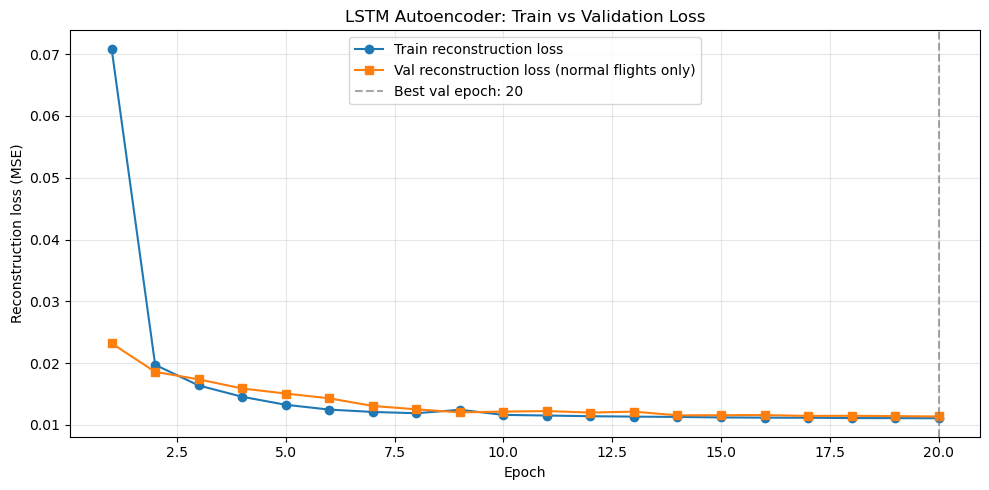

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_anomaly_score/plots/lstm_autoencoder_training_loss.png


In [53]:

# ============================================================
# CELL 20: Train/val loss plot  ← UPDATED
# Now shows both curves. Supervisor checks this for overfitting.
# ============================================================
epochs_ran = range(1, len(train_losses) + 1)
 
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(epochs_ran, train_losses, marker="o", label="Train reconstruction loss")
ax.plot(epochs_ran, val_losses,   marker="s", label="Val reconstruction loss (normal flights only)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Reconstruction loss (MSE)")
ax.set_title("LSTM Autoencoder: Train vs Validation Loss")
ax.legend()
ax.grid(True, alpha=0.3)
 
# Annotate best val epoch
best_epoch = int(np.argmin(val_losses)) + 1
ax.axvline(x=best_epoch, color="gray", linestyle="--", alpha=0.7,
           label=f"Best val epoch: {best_epoch}")
ax.legend()
 
plt.tight_layout()
loss_plot_path = PLOT_DIR / "lstm_autoencoder_training_loss.png"
plt.savefig(loss_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", loss_plot_path)


In [54]:

# ============================================================
# CELL 21: Anomaly scoring function  ← UPDATED (fixed zero-score bug)
# ============================================================
def score_dataframe_with_autoencoder(df_sorted, feature_cols, seq_len, stride, batch_size=64):
    """
    Scores every row with an anomaly_score = average MSE reconstruction error
    across all sliding windows that include that row.
 
    Rows at the very start/end of flights that are not covered by any window
    (fewer than seq_len rows from the flight boundary) are filled using
    forward/backward fill within the same flight, then global median as fallback.
 
    This uses score_count == 0 to detect uncovered rows, NOT replace(0, nan),
    so genuine zero reconstruction is preserved.
    """
    model.eval()
 
    X_array = df_sorted[feature_cols].to_numpy(dtype=np.float32)
 
    window_starts = build_window_starts(
        df_sorted, seq_len=seq_len, stride=stride, normal_only=False
    )
    print(f"  Scoring windows: {len(window_starts):,}")
 
    dataset = UAVSequenceDataset(X_array, window_starts, seq_len)
    loader  = DataLoader(dataset, batch_size=batch_size, shuffle=False, drop_last=False)
 
    score_sum   = np.zeros(len(df_sorted), dtype=np.float64)
    score_count = np.zeros(len(df_sorted), dtype=np.float64)
 
    with torch.no_grad():
        for batch_x, batch_starts in loader:
            batch_x     = batch_x.to(device)
            reconstructed = model(batch_x)
 
            # Per-timestep MSE averaged over features
            step_errors  = ((batch_x - reconstructed) ** 2).mean(dim=2)
            step_errors  = step_errors.cpu().numpy()
            batch_starts = batch_starts.numpy()
 
            for i, start in enumerate(batch_starts):
                end = start + seq_len
                score_sum[start:end]   += step_errors[i]
                score_count[start:end] += 1
 
    # FIXED: use score_count == 0, not replace(0, nan)
    anomaly_score = np.where(score_count > 0, score_sum / score_count, np.nan)
 
    scored_df = df_sorted.copy()
    scored_df["anomaly_score"] = anomaly_score
 
    uncovered = int(scored_df["anomaly_score"].isna().sum())
    if uncovered > 0:
        print(f"  Uncovered rows: {uncovered} — filling via ffill/bfill within flight")
        scored_df["anomaly_score"] = (
            scored_df
            .groupby("log_id")["anomaly_score"]
            .transform(lambda s: s.ffill().bfill())
        )
 
    still_missing = int(scored_df["anomaly_score"].isna().sum())
    if still_missing > 0:
        global_median = scored_df["anomaly_score"].median()
        scored_df["anomaly_score"] = scored_df["anomaly_score"].fillna(global_median)
        print(f"  Global median fill applied to {still_missing} rows")
 
    return scored_df

In [55]:

# ============================================================
# CELL 22: Load best model and score all splits
# ============================================================
model.load_state_dict(
    torch.load(
        OUTPUT_DIR / "best_lstm_autoencoder.pt",
        map_location=device,
        weights_only=True    # avoids FutureWarning in PyTorch 2.0+
    )
)
print("Best model loaded.\n")
 
print("Scoring train set...")
train_scored = score_dataframe_with_autoencoder(
    train_sorted, feature_cols, seq_len=SEQ_LEN, stride=STRIDE_SCORE, batch_size=BATCH_SIZE
)
 
print("\nScoring validation set...")
val_scored = score_dataframe_with_autoencoder(
    val_sorted, feature_cols, seq_len=SEQ_LEN, stride=STRIDE_SCORE, batch_size=BATCH_SIZE
)
 
print("\nScoring test set...")
test_scored = score_dataframe_with_autoencoder(
    test_sorted, feature_cols, seq_len=SEQ_LEN, stride=STRIDE_SCORE, batch_size=BATCH_SIZE
)
 
print("\nAnomaly scoring completed.")
 
# ============================================================
# CELL 23: Anomaly score summary statistics  ← UPDATED
# Prints mean/std/median for normal vs abnormal in each split.
# Give these numbers to your supervisor — not just plots.
# ============================================================
print("\n" + "="*65)
print("ANOMALY SCORE SUMMARY BY LABEL AND SPLIT")
print("="*65)
 
for split_name, df in [("Train", train_scored), ("Validation", val_scored), ("Test", test_scored)]:
    print(f"\n{split_name}:")
    summary = df.groupby("dataset_label")["anomaly_score"].agg(
        ["count", "mean", "std", "median",
         lambda x: x.quantile(0.95)]
    )
    summary.columns = ["n_rows", "mean", "std", "median", "p95"]
    print(summary.to_string())
 
# ============================================================
# CELL 24: AUROC and AUPRC  ← NEW (most important new addition)
# Without this, you have generated a number but not proved it works.
# Computed at flight level (mean score per flight vs binary label).
# ============================================================
print("\n" + "="*65)
print("FLIGHT-LEVEL ANOMALY DETECTION PERFORMANCE")
print("="*65)
print("Using per-flight mean anomaly score as the detection signal.")
print("Binary label: 1 = abnormal, 0 = normal\n")
 
for split_name, df in [("Train", train_scored), ("Validation", val_scored), ("Test", test_scored)]:
 
    flight_level = (
        df.groupby(["log_id", "dataset_label"])["anomaly_score"]
        .mean()
        .reset_index()
        .rename(columns={"anomaly_score": "mean_score"})
    )
    flight_level["binary_label"] = (flight_level["dataset_label"] == "abnormal").astype(int)
 
    n_normal   = (flight_level["binary_label"] == 0).sum()
    n_abnormal = (flight_level["binary_label"] == 1).sum()
    print(f"{split_name}: {n_normal} normal flights, {n_abnormal} abnormal flights")
 
    if flight_level["binary_label"].nunique() < 2:
        print(f"  → Only one class present — cannot compute AUROC/AUPRC.\n")
        continue
 
    auroc = roc_auc_score(flight_level["binary_label"], flight_level["mean_score"])
    auprc = average_precision_score(flight_level["binary_label"], flight_level["mean_score"])
 
    print(f"  Flight-level AUROC : {auroc:.4f}")
    print(f"  Flight-level AUPRC : {auprc:.4f}")
 
    # Baseline AUPRC = proportion of positives (random classifier)
    baseline_auprc = flight_level["binary_label"].mean()
    print(f"  Baseline AUPRC     : {baseline_auprc:.4f}  (random classifier = proportion of abnormal)")
    print()
 
# Store test flight level for plots
test_flight_level = (
    test_scored
    .groupby(["log_id", "dataset_label"])["anomaly_score"]
    .mean()
    .reset_index()
    .rename(columns={"anomaly_score": "mean_score"})
)
test_flight_level["binary_label"] = (test_flight_level["dataset_label"] == "abnormal").astype(int)
 

Best model loaded.

Scoring train set...
  Scoring windows: 68,353


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_69391/3397166892.py:47: RuntimeWarning: invalid value encountered in divide
  anomaly_score = np.where(score_count > 0, score_sum / score_count, np.nan)


  Uncovered rows: 489 — filling via ffill/bfill within flight

Scoring validation set...
  Scoring windows: 13,639


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_69391/3397166892.py:47: RuntimeWarning: invalid value encountered in divide
  anomaly_score = np.where(score_count > 0, score_sum / score_count, np.nan)


  Uncovered rows: 109 — filling via ffill/bfill within flight

Scoring test set...
  Scoring windows: 13,604
  Uncovered rows: 144 — filling via ffill/bfill within flight

Anomaly scoring completed.

ANOMALY SCORE SUMMARY BY LABEL AND SPLIT

Train:
               n_rows      mean       std    median       p95
dataset_label                                                
abnormal       197299  0.870946  1.997615  0.015712  5.686406
normal         497250  0.011438  0.039371  0.002408  0.043570

Validation:
               n_rows      mean       std    median       p95
dataset_label                                                
abnormal        46025  0.080457  0.090226  0.046619  0.183153
normal          92724  0.011398  0.023501  0.003540  0.044954

Test:
               n_rows      mean       std    median       p95
dataset_label                                                
abnormal        38118  0.008460  0.033215  0.001051  0.033302
normal         100406  0.023761  0.091492  0.0019

/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_69391/3397166892.py:47: RuntimeWarning: invalid value encountered in divide
  anomaly_score = np.where(score_count > 0, score_sum / score_count, np.nan)


In [56]:

# ============================================================
# CELL 25: Threshold definition  ← NEW
# Define a data-driven threshold: 95th percentile of TRAINING
# normal flight scores. Document this clearly for the thesis.
# ============================================================
train_normal_scores = train_scored.loc[
    train_scored["dataset_label"] == "normal", "anomaly_score"
]
 
ANOMALY_THRESHOLD = float(np.percentile(train_normal_scores, 95))
 
print(f"\nAnomaly threshold (95th pct of training normal scores): {ANOMALY_THRESHOLD:.6f}")
print("Justification: A flight row scoring above this threshold exceeds the")
print("reconstruction error seen in 95% of normal training data rows,")
print("indicating behaviour the autoencoder did not learn to reconstruct.")
 
# Apply threshold to test set
test_scored["anomaly_flag"] = (test_scored["anomaly_score"] > ANOMALY_THRESHOLD).astype(int)
train_scored["anomaly_flag"] = (train_scored["anomaly_score"] > ANOMALY_THRESHOLD).astype(int)
val_scored["anomaly_flag"]   = (val_scored["anomaly_score"]   > ANOMALY_THRESHOLD).astype(int)
 
flagged_pct = test_scored.groupby("dataset_label")["anomaly_flag"].mean() * 100
print("\nProportion of rows flagged as anomalous (test set):")
print(flagged_pct.to_string())


Anomaly threshold (95th pct of training normal scores): 0.043570
Justification: A flight row scoring above this threshold exceeds the
reconstruction error seen in 95% of normal training data rows,
indicating behaviour the autoencoder did not learn to reconstruct.

Proportion of rows flagged as anomalous (test set):
dataset_label
abnormal    3.814471
normal      7.953708


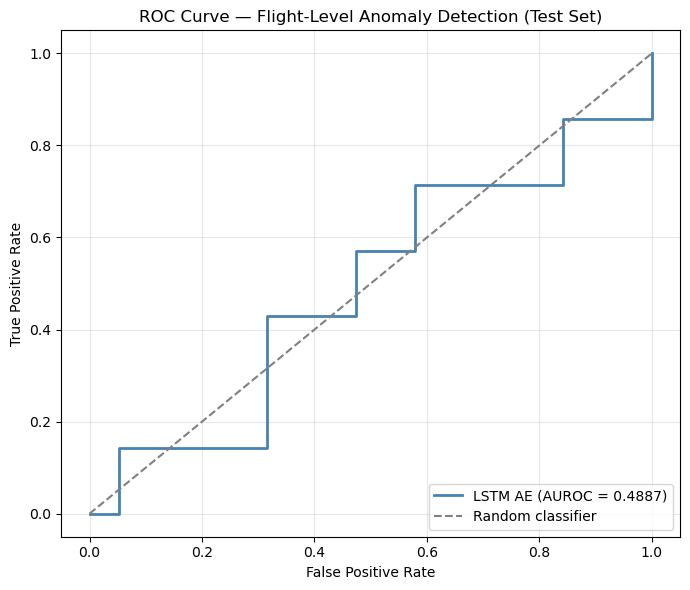

Saved: roc_curve_flight_level.png


In [57]:

# ============================================================
# CELL 26: ROC curve plot  ← NEW
# ============================================================
if test_flight_level["binary_label"].nunique() == 2:
 
    fpr, tpr, thresholds_roc = roc_curve(
        test_flight_level["binary_label"],
        test_flight_level["mean_score"]
    )
    auroc_test = roc_auc_score(
        test_flight_level["binary_label"],
        test_flight_level["mean_score"]
    )
 
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(fpr, tpr, color="steelblue", lw=2, label=f"LSTM AE (AUROC = {auroc_test:.4f})")
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random classifier")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC Curve — Flight-Level Anomaly Detection (Test Set)")
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "roc_curve_flight_level.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved: roc_curve_flight_level.png")
 
else:
    print("Only one class in test set — ROC curve skipped.")

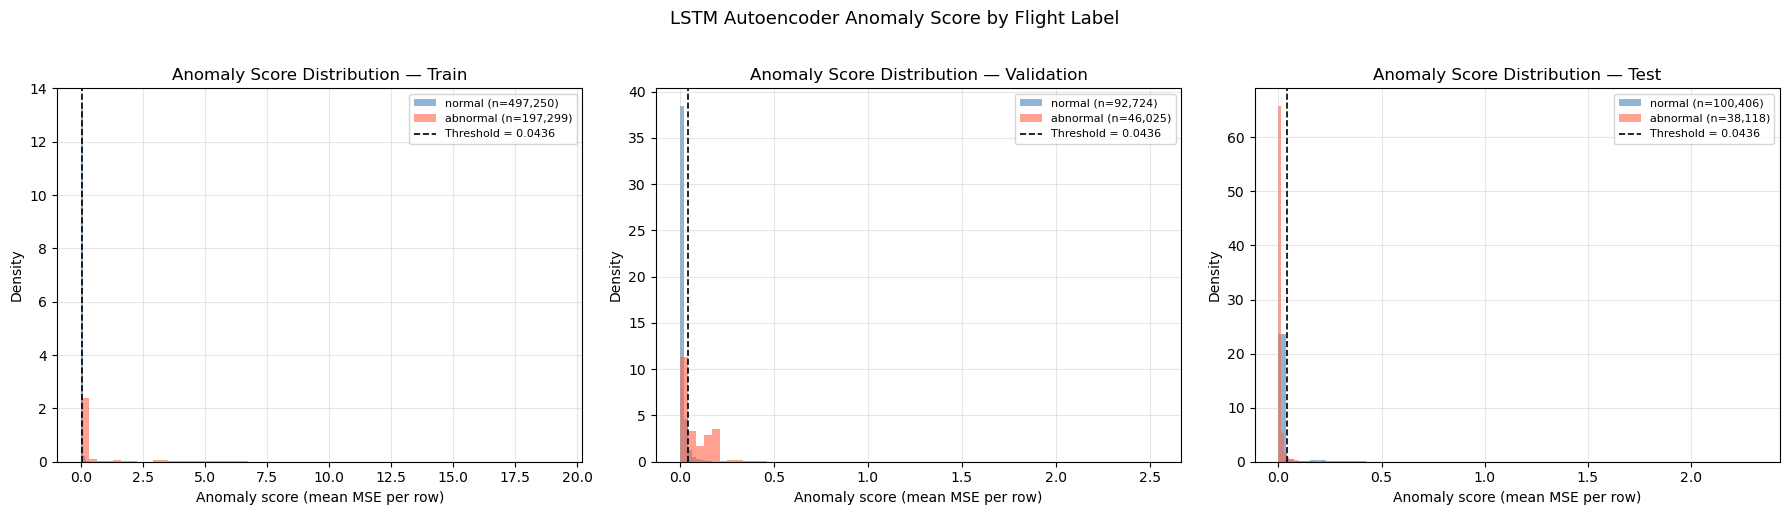

Saved: anomaly_score_distribution_all_splits.png


In [58]:

# ============================================================
# CELL 27: PLOT A — Train/val/test distribution  ← UPDATED
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
 
for ax, (split_name, df) in zip(axes, [
    ("Train", train_scored), ("Validation", val_scored), ("Test", test_scored)
]):
    for label, color in [("normal", "steelblue"), ("abnormal", "tomato")]:
        subset = df[df["dataset_label"] == label]
        if len(subset) > 0:
            ax.hist(
                subset["anomaly_score"],
                bins=60, alpha=0.6,
                label=f"{label} (n={len(subset):,})",
                color=color, density=True
            )
    ax.axvline(ANOMALY_THRESHOLD, color="black", linestyle="--",
               linewidth=1.2, label=f"Threshold = {ANOMALY_THRESHOLD:.4f}")
    ax.set_title(f"Anomaly Score Distribution — {split_name}")
    ax.set_xlabel("Anomaly score (mean MSE per row)")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
 
plt.suptitle("LSTM Autoencoder Anomaly Score by Flight Label", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(PLOT_DIR / "anomaly_score_distribution_all_splits.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: anomaly_score_distribution_all_splits.png")

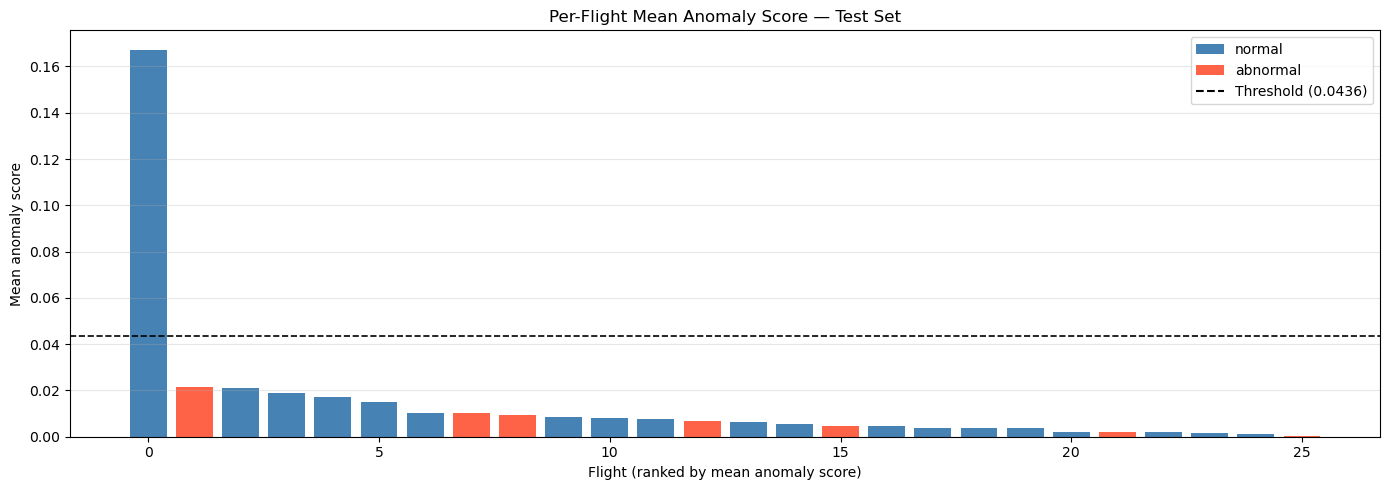

Saved: per_flight_anomaly_score_test.png


In [59]:

# ============================================================
# CELL 28: PLOT B — Per-flight mean anomaly score (test set)
# ============================================================
flight_scores = (
    test_scored
    .groupby(["log_id", "dataset_label"])["anomaly_score"]
    .mean()
    .reset_index()
    .sort_values("anomaly_score", ascending=False)
    .reset_index(drop=True)
)
 
colors_bar = flight_scores["dataset_label"].map({"normal": "steelblue", "abnormal": "tomato"})
 
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(range(len(flight_scores)), flight_scores["anomaly_score"], color=colors_bar)
ax.axhline(ANOMALY_THRESHOLD, color="black", linestyle="--",
           linewidth=1.2, label=f"Threshold = {ANOMALY_THRESHOLD:.4f}")
ax.set_xlabel("Flight (ranked by mean anomaly score)")
ax.set_ylabel("Mean anomaly score")
ax.set_title("Per-Flight Mean Anomaly Score — Test Set")
ax.set_ylim(bottom=0)
 
legend_elements = [
    mpatches.Patch(facecolor="steelblue", label="normal"),
    mpatches.Patch(facecolor="tomato",    label="abnormal"),
    plt.Line2D([0], [0], color="black", linestyle="--", label=f"Threshold ({ANOMALY_THRESHOLD:.4f})")
]
ax.legend(handles=legend_elements)
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(PLOT_DIR / "per_flight_anomaly_score_test.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: per_flight_anomaly_score_test.png")

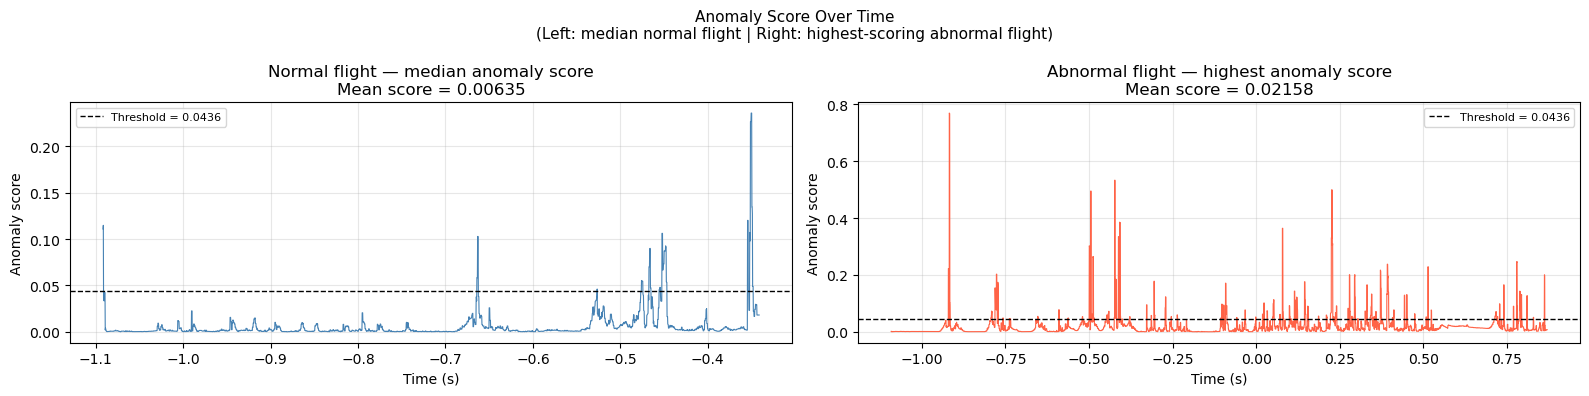

Saved: anomaly_score_over_time_normal_vs_abnormal.png

Chosen normal flight   : e07140ce-5b0d-433d-80e2-25845371a6f9 (median of normal group)
Chosen abnormal flight : c839b5f0-b619-4e68-92e6-5b9a82465c72 (highest mean score in abnormal group)


In [60]:

# ============================================================
# CELL 29: PLOT C — Anomaly score over time  ← UPDATED
# Now picks the MEDIAN normal flight and HIGHEST scored abnormal
# flight, so the choice is principled and defensible to supervisor.
# ============================================================
 
# Pick representative normal flight: closest to median normal score
normal_flight_scores = (
    test_scored[test_scored["dataset_label"] == "normal"]
    .groupby("log_id")["anomaly_score"].mean()
)
abnormal_flight_scores = (
    test_scored[test_scored["dataset_label"] == "abnormal"]
    .groupby("log_id")["anomaly_score"].mean()
)
 
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
 
if len(normal_flight_scores) > 0:
    # Median normal flight (most representative)
    median_val   = normal_flight_scores.median()
    chosen_normal = (normal_flight_scores - median_val).abs().idxmin()
    sample_normal = test_scored[test_scored["log_id"] == chosen_normal]
 
    axes[0].plot(sample_normal["time_s"].values, sample_normal["anomaly_score"].values,
                 color="steelblue", linewidth=0.8)
    axes[0].axhline(ANOMALY_THRESHOLD, color="black", linestyle="--",
                    linewidth=1, label=f"Threshold = {ANOMALY_THRESHOLD:.4f}")
    axes[0].set_title(
        f"Normal flight — median anomaly score\n"
        f"Mean score = {normal_flight_scores[chosen_normal]:.5f}"
    )
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Anomaly score")
    axes[0].legend(fontsize=8)
    axes[0].grid(True, alpha=0.3)
 
if len(abnormal_flight_scores) > 0:
    # Highest scored abnormal flight (clearest case to show)
    chosen_abnormal = abnormal_flight_scores.idxmax()
    sample_abnormal = test_scored[test_scored["log_id"] == chosen_abnormal]
 
    axes[1].plot(sample_abnormal["time_s"].values, sample_abnormal["anomaly_score"].values,
                 color="tomato", linewidth=0.8)
    axes[1].axhline(ANOMALY_THRESHOLD, color="black", linestyle="--",
                    linewidth=1, label=f"Threshold = {ANOMALY_THRESHOLD:.4f}")
    axes[1].set_title(
        f"Abnormal flight — highest anomaly score\n"
        f"Mean score = {abnormal_flight_scores[chosen_abnormal]:.5f}"
    )
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Anomaly score")
    axes[1].legend(fontsize=8)
    axes[1].grid(True, alpha=0.3)
else:
    axes[1].text(0.5, 0.5, "No abnormal flights in test set", ha="center", va="center",
                 transform=axes[1].transAxes)
    axes[1].set_title("Abnormal flight — none in test set")
 
plt.suptitle(
    "Anomaly Score Over Time\n"
    "(Left: median normal flight | Right: highest-scoring abnormal flight)",
    fontsize=11
)
plt.tight_layout()
plt.savefig(PLOT_DIR / "anomaly_score_over_time_normal_vs_abnormal.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: anomaly_score_over_time_normal_vs_abnormal.png")
print(f"\nChosen normal flight   : {chosen_normal} (median of normal group)")
if len(abnormal_flight_scores) > 0:
    print(f"Chosen abnormal flight : {chosen_abnormal} (highest mean score in abnormal group)")

In [61]:

# ============================================================
# CELL 30: Save scored datasets  (restore original row order)
# ============================================================
def restore_and_save(scored_df, save_path):
    output_df = (
        scored_df
        .sort_values("_original_order")
        .drop(columns=["_original_order"])
        .reset_index(drop=True)
    )
    output_df.to_csv(save_path, index=False)
    print(f"Saved : {save_path}")
    print(f"Shape : {output_df.shape}")
    print(f"Missing anomaly_score: {output_df['anomaly_score'].isna().sum()}")
    return output_df
 
 
train_out = restore_and_save(train_scored, OUTPUT_DIR / "train_no_dr_with_anomaly_score.csv")
val_out   = restore_and_save(val_scored,   OUTPUT_DIR / "val_no_dr_with_anomaly_score.csv")
test_out  = restore_and_save(test_scored,  OUTPUT_DIR / "test_no_dr_with_anomaly_score.csv")


Saved : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_anomaly_score/train_no_dr_with_anomaly_score.csv
Shape : (694549, 16)
Missing anomaly_score: 0
Saved : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_anomaly_score/val_no_dr_with_anomaly_score.csv
Shape : (138749, 16)
Missing anomaly_score: 0
Saved : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_anomaly_score/test_no_dr_with_anomaly_score.csv
Shape : (138524, 16)
Missing anomaly_score: 0


In [62]:

# ============================================================
# CELL 31: Final checks
# ============================================================
print("\n" + "="*60)
print("FINAL OUTPUT SUMMARY")
print("="*60)
 
for split_name, df in [("Train", train_out), ("Val", val_out), ("Test", test_out)]:
    print(f"\n{split_name}:")
    print(f"  Shape            : {df.shape}")
    print(f"  Columns          : {df.columns.tolist()}")
    print(f"  anomaly_score NaN: {df['anomaly_score'].isna().sum()}")
    print(f"  anomaly_score mean (normal)   : "
          f"{df.loc[df['dataset_label']=='normal','anomaly_score'].mean():.6f}")
    if (df["dataset_label"] == "abnormal").any():
        print(f"  anomaly_score mean (abnormal) : "
              f"{df.loc[df['dataset_label']=='abnormal','anomaly_score'].mean():.6f}")
 
print("\nNotebook 05 complete.")
print("Output files ready for notebook 06_anomaly_aware_models.ipynb")
 


FINAL OUTPUT SUMMARY

Train:
  Shape            : (694549, 16)
  Columns          : ['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'target_energy_next_60s_wh', 'anomaly_score', 'anomaly_flag']
  anomaly_score NaN: 0
  anomaly_score mean (normal)   : 0.011438
  anomaly_score mean (abnormal) : 0.870946

Val:
  Shape            : (138749, 16)
  Columns          : ['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'target_energy_next_60s_wh', 'ano